## 1. Imports

The Arrow-backed reads require pandas 2.0 or newer and pyarrow.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the raw data

In [2]:
# Support running from either the project root or notebooks/.
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw = root / "data" / "raw"
# Arrow-backed columns and chunked parsing reduce memory overhead.
transactions = pd.concat(
    pd.read_csv(raw / "train_transaction.csv", chunksize=25_000, dtype_backend="pyarrow"),
    ignore_index=True,
)
identity = pd.read_csv(raw / "train_identity.csv", dtype_backend="pyarrow")

## 3. Merge the datasets

In [3]:
merged = transactions.merge(identity, on="TransactionID", how="left")
del transactions, identity  # Release the original frames.
print("Merged shape:", merged.shape)

Merged shape: (590540, 434)


## 4. Fraud counts and percentages

In [4]:
counts = merged["isFraud"].value_counts().reindex([0, 1], fill_value=0)
fraud_rate = pd.DataFrame({"count": counts, "percentage": counts / len(merged) * 100})
print(fraud_rate)

          count  percentage
isFraud                    
0        569877   96.500999
1         20663    3.499001


## 5. Class imbalance

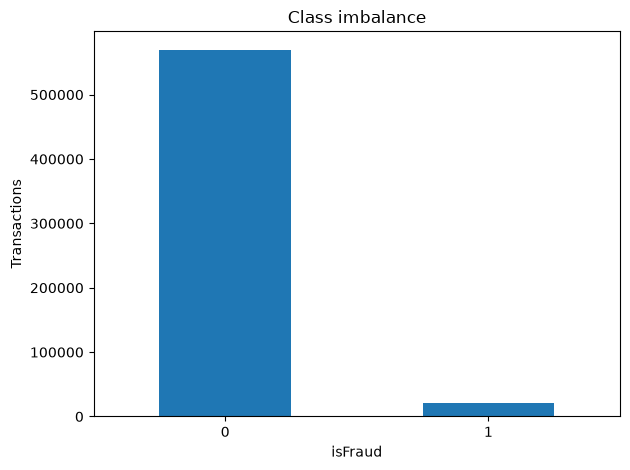

In [5]:
fig, ax = plt.subplots()
counts.plot.bar(ax=ax, rot=0, xlabel="isFraud", ylabel="Transactions", title="Class imbalance")
plt.tight_layout()
plt.show()
plt.close(fig)

## 6. Columns with the most missing values

In [6]:
# Check one column at a time instead of allocating a full-frame mask.
missing = pd.Series({col: merged[col].isna().mean() * 100 for col in merged.columns})
print(missing.nlargest(15).rename("missing percentage"))

id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_22    99.124699
id_23    99.124699
id_27    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
Name: missing percentage, dtype: float64


## 7. Transaction amounts by fraud class

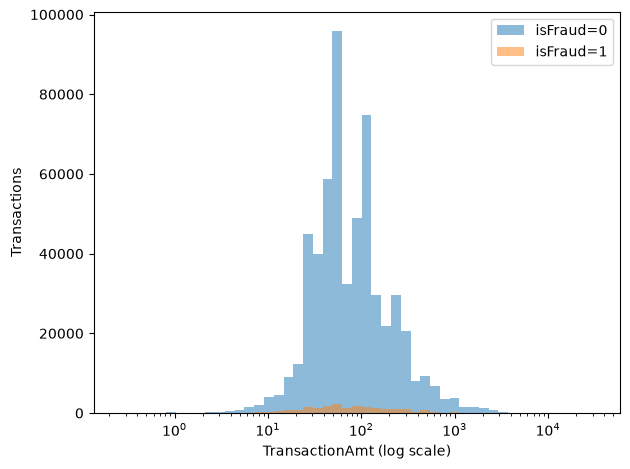

In [7]:
# A logarithmic x-axis requires positive amounts.
amount = merged["TransactionAmt"]
positive = amount[amount > 0]
bins = np.logspace(np.log10(float(positive.min())) - 0.01,
                   np.log10(float(positive.max())) + 0.01, 50)
fig, ax = plt.subplots()
for label in [0, 1]:
    values = amount[(merged["isFraud"] == label) & (amount > 0)]
    plt.hist(values.to_numpy(dtype="float64", na_value=np.nan), bins=bins,
             alpha=0.5, label=f"isFraud={label}")
plt.xscale("log")
plt.xlabel("TransactionAmt (log scale)")
plt.ylabel("Transactions")
plt.legend()
plt.tight_layout()
plt.show()
plt.close(fig)
del amount, positive, values

## 8. Fraud rate by product

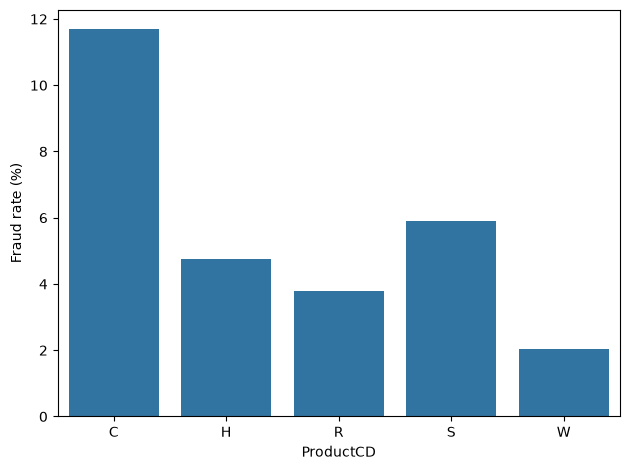

In [8]:
product_rate = merged.groupby("ProductCD")["isFraud"].mean().astype(float) * 100
fig, ax = plt.subplots()
sns.barplot(x=product_rate.index, y=product_rate.values, ax=ax)
plt.xlabel("ProductCD")
plt.ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()
plt.close(fig)

## 9. Save the merged data

In [9]:
output = root / "data" / "processed" / "merged.parquet"
output.parent.mkdir(parents=True, exist_ok=True)
merged.to_parquet(output, index=False)
print("Saved:", output)

Saved: c:\Realtime-fraud-platform\data\processed\merged.parquet


## 10. Evaluation metric

Fraud is only a few percent of the data, so we will use PR-AUC instead of accuracy.